## Items to do:
need to organize code more. Note:
1. where is skip heights
2. inputs from config file

Assess impacts of fit options (affect Chi2)
1. single scaling (fixed activity ratio)
2. variable bins vs fixed bins (chi2)
3. impact of first bin
4. lower stats (profile likelihood)?

attenuation goes opposite way... should add reflector at top of chamber

In [66]:
## Atown's stuff
import os
import sys
import time
sys.path.append("..")
from globalsC2 import *

import sys

import matplotlib.pyplot as plt
import numpy as np
import PickleLite as PL

# import MakeSpectra as MS
print(COMP2PATH)

/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2


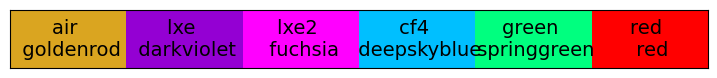

In [67]:
## Style setup — PDEStyle colors + larger fonts
import PDEStyle as PS
ms = PS.MyStyleSet()
ms.SetMPLcolors()   # sets matplotlib prop_cycle to PDEStyle colors

ms.show()

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 11,
})

In [68]:
from datetime import datetime

def days_between(date1, date2, fmt="%Y-%m-%d"):
    """Return the number of days between two dates (date2 - date1)."""
    d1 = datetime.strptime(date1, fmt)
    d2 = datetime.strptime(date2, fmt)
    return np.abs((d2 - d1).days)
  
def ReducedActivity(days, hlife):
    """Calculate the reduced activity of a radioactive isotope after a certain number of days, given its half-life."""
    return 0.5 ** (days / hlife)

In [ ]:
actCo = 4713000
actCs = 135500

actRatio = actCo / actCs
print("Activity Ratio Co-60 / Cs-137: ", actRatio)

thetaOpening = np.arctan(2/100)*180/np.pi
print("Detector opening angle (degrees): ", thetaOpening, "deg \n\n")

func_thetaOpen = lambda size, length: np.arctan(size/2/length)*180/np.pi
func_fOmega = lambda theta: (1 - np.cos(theta * np.pi / 180)) / 2

fOmega = (1 - np.cos(1.5 * np.pi / 180))/2  # fraction of 4pi covered by detector at 1.5 degrees
print("fOmega (fraction of 4pi covered by collimator): ", fOmega)
print("scaled Co rate", fOmega * actCo)
print("scaled Cs rate", fOmega * actCs)

print()
print(f"3mm: {func_thetaOpen(3, 100):0.2f} deg, fOmega: {func_fOmega(func_thetaOpen(3, 100)):0.1e}")
print(f"4mm: {func_thetaOpen(4, 100):0.2f} deg, fOmega: {func_fOmega(func_thetaOpen(4, 100)):0.1e}")

print(f"3mm, forward 2cm: {func_thetaOpen(3, 100-20):0.2f} deg, fOmega: {func_fOmega(func_thetaOpen(3, 100-20)) :0.1e}")
print()

##########
Ci2Beq = 3.7e10
dataDate = "2022-03-01"

actCs_2 = 11.1e-6 * Ci2Beq
dateCs = "1974-06-01"
hlCs = 30.17 * 365  # in days
daysCs = days_between(dateCs, dataDate)

actCo_2 = 6.2e-3 * Ci2Beq
dateCo = "2018-01-16"
daysCo = days_between(dateCo, dataDate)
hlCo = 271.8
# print("Days since Cs-137 was produced: ", daysCs)
# print("activity reduction",ReducedActivity(daysCs, hlCs))

actCs_calc = actCs_2 * ReducedActivity(daysCs, hlCs)
print("original Cs-137 activity: ", actCs_2)
print("calculated Cs-137 activity: ", actCs_calc)

actCo_calc = actCo_2 * ReducedActivity(daysCo, hlCo)
print("original Co-60 activity: ", actCo_2)
print("calculated Co-60 activity: ", actCo_calc)

## overwrite activities with calculated values
actCs = actCs_calc
actCo = actCo_calc

Activity Ratio Co-60 / Cs-137:  34.78228782287823
Detector opening angle (degrees):  1.1457628381751035 deg 


fOmega (fraction of 4pi covered by collimator):  0.00017133751222137006
scaled Co rate 807.513695099317
scaled Cs rate 23.216232905995643

3mm: 0.86 deg, fOmega: 5.6e-05
4mm: 1.15 deg, fOmega: 1.0e-04
3mm, forward 2cm: 1.07 deg, fOmega: 8.8e-05

original Cs-137 activity:  410700.0
calculated Cs-137 activity:  137017.98697404933
original Co-60 activity:  229400000.0
calculated Co-60 activity:  4940174.165757093


In [70]:
# Example usage (uncomment and set COMP2PATH if not already in scope):
save_dir = os.path.join(COMP2PATH, "DataAnalysis", "saved_spectra2")

## opening multiple in one file
co_bare = PL.load_snap_list(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"))
print(type(co_bare[0]))
print(f"Loaded {len(co_bare)} Co bare LiteRun objects. First IDs:", [lr.id for lr in co_bare[:3]])

# Optional: tiny loader example which also works
# with open(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"), "rb") as f:
#   co_bare_loaded = pickle.load(f)
#   print(f"Loaded {len(co_bare_loaded)} Co bare snapshots. First IDs:", [d["id"] for d in co_bare_loaded[:3]])
#   print(type(co_bare_loaded[0]))

<class 'PickleLite.LiteRun'>
Loaded 5 Co bare LiteRun objects. First IDs: ['202203031411', '202203031118', '202203031135']


---
### Load data spectra

166300
110521
130428


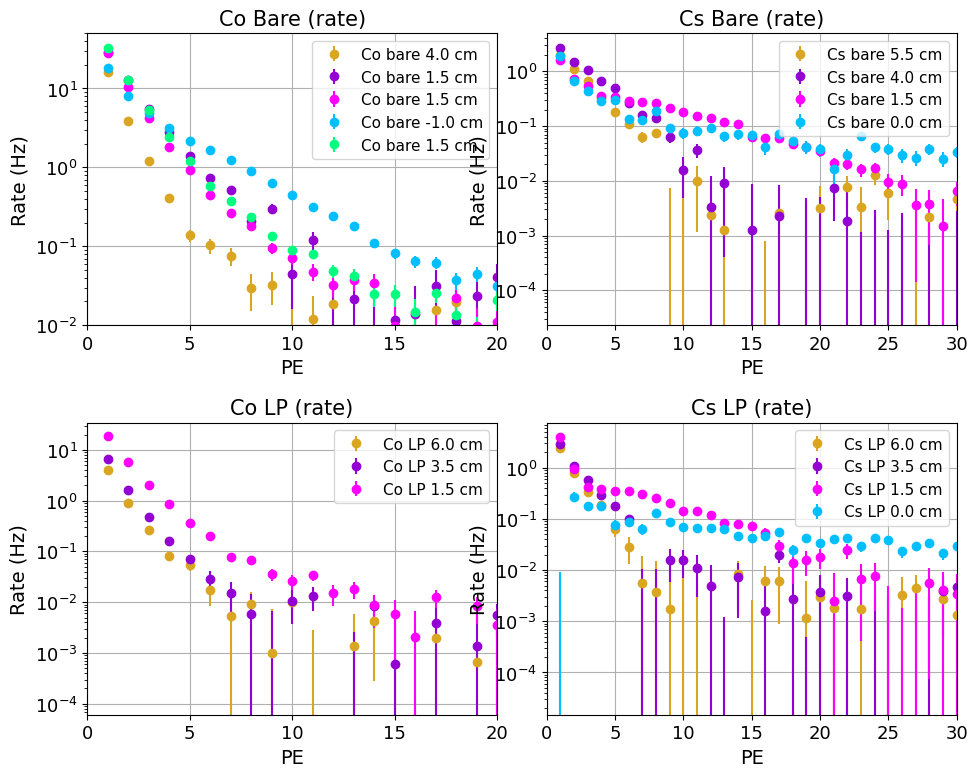

In [71]:
save_dir = os.path.join(COMP2PATH, "DataAnalysis", "saved_spectra2")

co_bare = PL.load_snap_list(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"))
cs_bare = PL.load_snap_list(os.path.join(save_dir, "rc_Cs_bare_source.snap.pkl"))
co_lp = PL.load_snap_list(os.path.join(save_dir, "rc_Co_LP_source.snap.pkl"))
cs_lp = PL.load_snap_list(os.path.join(save_dir, "rc_Cs_LP_source.snap.pkl"))

# Plot one example per category
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
hsub = 32
# hsub = 0

for lr in co_bare:
  lr.mpl_errorbar(axes[0,0], useCounts=False, label=f"Co bare {hsub - lr.height} cm", marker='o', linestyle='None')
axes[0,0].set_yscale('log'); axes[0,0].set_title("Co Bare (rate)"); axes[0,0].legend(); axes[0,0].grid(True)

for lr in cs_bare:
  lr.mpl_errorbar(axes[0,1], useCounts=False, label=f"Cs bare {hsub - lr.height} cm", marker='o', linestyle='None')
axes[0,1].set_yscale('log'); axes[0,1].set_title("Cs Bare (rate)"); axes[0,1].legend(); axes[0,1].grid(True)

for lr in co_lp:
  lr.mpl_errorbar(axes[1,0], useCounts=False, label=f"Co LP {hsub - lr.height} cm", marker='o', linestyle='None')
axes[1,0].set_yscale('log'); axes[1,0].set_title("Co LP (rate)"); axes[1,0].legend(); axes[1,0].grid(True)

for lr in cs_lp:
  lr.mpl_errorbar(axes[1,1], useCounts=False, label=f"Cs LP {hsub - lr.height} cm", marker='o', linestyle='None')
axes[1,1].set_yscale('log'); axes[1,1].set_title("Cs LP (rate)"); axes[1,1].legend(); axes[1,1].grid(True)

for rl in co_lp:
  print(np.sum(rl.counts_raw))

for ax in axes.flat:
  ax.set_xlabel("PE"); ax.set_ylabel("Rate (Hz)")
  # ax.set_xlim(0, 5)

axes[0,0].set_ylim(1e-2, 50)

axes[0,0].set_xlim(0, 20)
axes[1,0].set_xlim(0, 20)

axes[0,1].set_xlim(0, 30)
axes[1,1].set_xlim(0, 30)

# fig.suptitle("Bacgkground-subtracted Spectra loaded from Pickle", fontsize=16)
plt.tight_layout(w_pad=-2); plt.show()

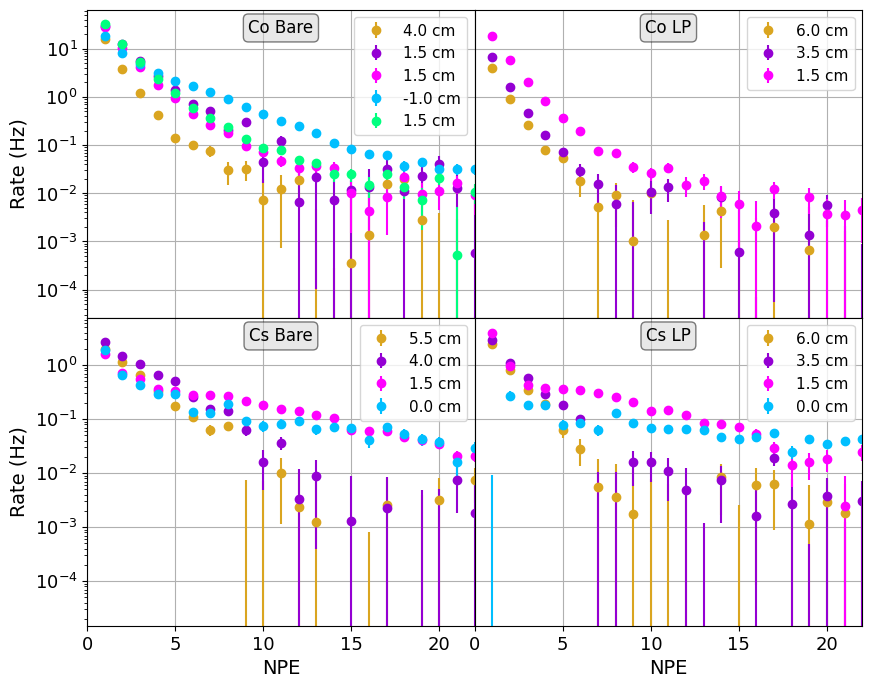

In [72]:
## Same data, re-oriented: rows = source (Co/Cs), columns = filter (Bare/LP), shared y per row
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey='row')

_tag_kw = dict(ha='center', va='top', fontsize=12,
               bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgray', alpha=0.5, edgecolor='black'))

# Row 0: Co
for lr in co_bare:
  lr.mpl_errorbar(axes[0,0], useCounts=False, label=f"{hsub - lr.height} cm", marker='o', linestyle='None')
axes[0,0].legend(); axes[0,0].grid(True)
axes[0,0].text(0.5, 0.97, "Co Bare", transform=axes[0,0].transAxes, **_tag_kw)

for lr in co_lp:
  lr.mpl_errorbar(axes[0,1], useCounts=False, label=f"{hsub - lr.height} cm", marker='o', linestyle='None')
axes[0,1].legend(); axes[0,1].grid(True)
axes[0,1].text(0.5, 0.97, "Co LP", transform=axes[0,1].transAxes, **_tag_kw)

# Row 1: Cs
for lr in cs_bare:
  lr.mpl_errorbar(axes[1,0], useCounts=False, label=f"{hsub - lr.height} cm", marker='o', linestyle='None')
axes[1,0].legend(); axes[1,0].grid(True)
axes[1,0].text(0.5, 0.97, "Cs Bare", transform=axes[1,0].transAxes, **_tag_kw)

for lr in cs_lp:
  lr.mpl_errorbar(axes[1,1], useCounts=False, label=f"{hsub - lr.height} cm", marker='o', linestyle='None')
axes[1,1].legend(); axes[1,1].grid(True)
axes[1,1].text(0.5, 0.97, "Cs LP", transform=axes[1,1].transAxes, **_tag_kw)

for ax in axes.flat:
  ax.set_yscale('log')
  ax.set_xlim(0, 22)
axes[1, 0].set_xlabel("NPE")
axes[1, 1].set_xlabel("NPE")

# Only left column gets y-label
axes[0,0].set_ylabel("Rate (Hz)")
axes[1,0].set_ylabel("Rate (Hz)")

axes[0, 0].tick_params(bottom=False, labelbottom=False)
axes[0, 1].tick_params(bottom=False, labelbottom=False)

axes[0, 1].tick_params(which='both', left=False, labelleft=False)
axes[1, 1].tick_params(which='both', left=False, labelleft=False)

fig.subplots_adjust(wspace=0.0, hspace=0.)
plt.show()


In [73]:
## more plotting o fpickle objects here

co_bare eff heights: ['4.00', '1.50', '1.50', '-1.00', '1.50']
co_lp eff heights:   ['6.00', '3.50', '1.50']
cs_bare eff heights: ['5.50', '4.00', '1.50', '0.00']
cs_lp eff heights:   ['6.00', '3.50', '1.50', '0.00']


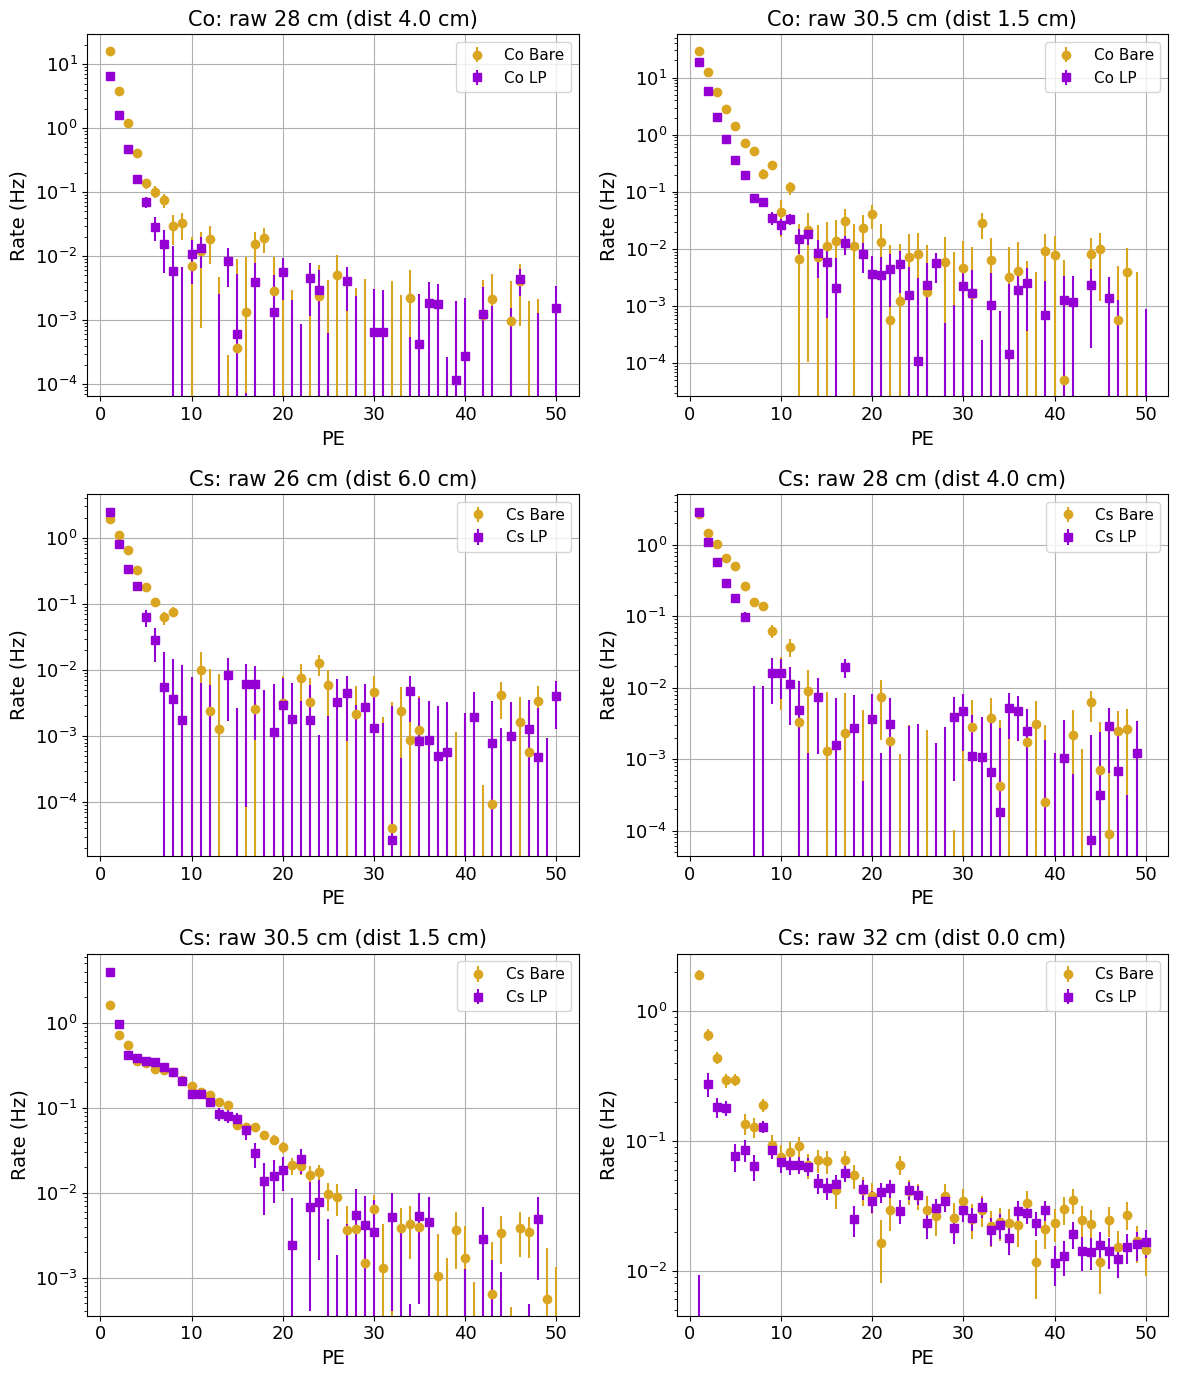

In [74]:
## Overlay Bare vs LP at matching heights for Co and Cs
hScale_nominal = compConfig["experiment"]["heightScale"] if 'compConfig' in vars() else 32.0
buf = 0.6

def get_eff_height(rc, hScale=hScale_nominal):
    """Return distance height - subtract hScale if raw height (>=25), otherwise already a distance."""
    if rc.mHeight >= 25:
        return hScale - rc.mHeight
    return rc.mHeight

def find_by_eff_height(lst, target, buf=buf):
    return next((rc for rc in lst if abs(get_eff_height(rc) - target) < buf), None)

print("co_bare eff heights:", [f"{get_eff_height(rc):.2f}" for rc in co_bare])
print("co_lp eff heights:  ", [f"{get_eff_height(rc):.2f}" for rc in co_lp])
print("cs_bare eff heights:", [f"{get_eff_height(rc):.2f}" for rc in cs_bare])
print("cs_lp eff heights:  ", [f"{get_eff_height(rc):.2f}" for rc in cs_lp])

## Co: raw 28->dist 4.0, raw 30.5->dist 1.5
## Cs: raw 26->dist 6.0, raw 28->dist 4.0, raw 30.5->dist 1.5, raw 32->dist 0.0
co_eff_targets = [4.0, 1.5]
co_raw_labels  = [28,  30.5]
cs_eff_targets = [6.0, 4.0, 1.5, 0.0]
cs_raw_labels  = [26,  28,  30.5, 32]

## 3x2 layout: row 0 = Co (2 heights), rows 1-2 = Cs (4 heights)
fig, axes = plt.subplots(3, 2, figsize=(12, 14))

for col, (eff_h, raw_h) in enumerate(zip(co_eff_targets, co_raw_labels)):
    ax = axes[0, col]
    b = find_by_eff_height(co_bare, eff_h)
    l = find_by_eff_height(co_lp,   eff_h)
    if b: b.mpl_errorbar(ax, useCounts=False, label=f"Co Bare", marker='o', linestyle='None')
    else: print(f"WARNING: Co bare not found for eff_h={eff_h} (raw {raw_h})")
    if l: l.mpl_errorbar(ax, useCounts=False, label=f"Co LP",   marker='s', linestyle='None')
    else: print(f"WARNING: Co LP not found for eff_h={eff_h} (raw {raw_h})")
    ax.set_yscale('log'); ax.set_title(f"Co: raw {raw_h} cm (dist {eff_h} cm)")
    ax.set_xlabel("PE"); ax.set_ylabel("Rate (Hz)"); ax.legend(); ax.grid(True)

cs_positions = [(1, 0), (1, 1), (2, 0), (2, 1)]
for (row, col), (eff_h, raw_h) in zip(cs_positions, zip(cs_eff_targets, cs_raw_labels)):
    ax = axes[row, col]
    b = find_by_eff_height(cs_bare, eff_h)
    l = find_by_eff_height(cs_lp,   eff_h)
    if b: b.mpl_errorbar(ax, useCounts=False, label=f"Cs Bare", marker='o', linestyle='None')
    else: print(f"WARNING: Cs bare not found for eff_h={eff_h} (raw {raw_h})")
    if l: l.mpl_errorbar(ax, useCounts=False, label=f"Cs LP",   marker='s', linestyle='None')
    else: print(f"WARNING: Cs LP not found for eff_h={eff_h} (raw {raw_h})")
    ax.set_yscale('log'); ax.set_title(f"Cs: raw {raw_h} cm (dist {eff_h} cm)")
    ax.set_xlabel("PE"); ax.set_ylabel("Rate (Hz)"); ax.legend(); ax.grid(True)

plt.tight_layout(); plt.show()

In [75]:
# for analysis just use:
# Co 28, 26
# Cs 30.5, 28, 

In [76]:
## getting rid of extra 30.5 cm runs
print("co_bare heights:", [rc.mHeight for rc in co_bare])


if len(co_bare) > 3:
  last_305_idx = max(i for i, rc in enumerate(co_bare) if rc.mHeight == 30.5)
  co_bare = [rc for i, rc in enumerate(co_bare) if rc.mHeight != 30.5 or i == last_305_idx]
  print("Kept heights:", [rc.mHeight for rc in co_bare])

co_bare heights: [28.0, 30.5, 30.5, 33.0, 30.5]
Kept heights: [28.0, 33.0, 30.5]


In [77]:
import json5 as json 
import CompHelpers.MCdataSet as MCH
import CompHelpers.Comparator_generic as COMP
import CompHelpers.RealDataSet as RD

with open("compConfig.json") as f:
  compConfig = json.load(f)

hSkipList = compConfig["comparison"]["hSkipList"]
print("hSkipList:", hSkipList)

with open(os.path.join(COMP2PATH, "pyScripts", "analysis.json")) as f:
  anaConfig = json.load(f)["analysis"]

hSkipList: [-1, 0]


In [78]:
rds = RD.RealDataSet()

print(type(co_bare[0]))  # Should print the type of the first LiteRun object

rds.mCoLP = co_lp
rds.mCsLP = cs_lp
rds.mCo = co_bare
rds.mCs = cs_bare

print(rds.mCo[0].mNEvents)

if rds.mCo[0].mHeight > 10: # if any height > 10 apply height scaling
  rds.ModifyHeights(hScale = compConfig["experiment"]["heightScale"])

## Rebin real data to match MC binning (from analysis.json)
rds.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"])
print(f"Real data rebinned to {anaConfig['nBins']} bins [{anaConfig['binLow']}-{anaConfig['binHigh']}]")

rds.print()

<class 'PickleLite.LiteRun'>
50058
Real data rebinned to 50 bins [0.5-50.5]

---- RealDataSet print() ----

    h         Nraw        Nsub     rate (Hz)    subRate (Hz)Cs:
|    5.5 |  6.0e+04  |  9.10e+03  |   29.46 |   4.48
|    4.0 |  5.1e+04  |  1.11e+04  |   32.00 |   7.02
|    1.5 |  1.0e+05  |  1.89e+04  |   30.75 |   5.77
|    0.0 |  2.5e+04  |  4.39e+03  |   30.60 |   5.62

Co:
|    4.0 |  5.0e+04  |  2.32e+04  |   46.87 |  21.89
|   -1.0 |  7.3e+04  |  4.62e+04  |   67.96 |  42.98
|    1.5 |  1.7e+05  |  1.19e+05  |   81.38 |  56.40

Cs LP:
|    6.0 |  5.3e+04  |  5.25e+03  |   39.10 |   3.90
|    3.5 |  6.1e+04  |  7.73e+03  |   40.37 |   5.18
|    1.5 |  3.0e+04  |  5.39e+03  |   43.19 |   7.99
|    0.0 |  5.1e+04  |  2.99e+03  |   37.41 |   2.21

Co LP:
|    6.0 |  1.7e+05  |  2.21e+04  |   40.59 |   5.39
|    3.5 |  1.1e+05  |  2.24e+04  |   44.15 |   8.95
|    1.5 |  1.3e+05  |  5.79e+04  |   63.33 |  28.13


---
## load tools and MC spectra

In [79]:
# pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/gammaLP_apr17_rerunAgain_moreStats/"

# pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/gammaLP_ap17_swapped5cm/"

# pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/gammaBare_may24_nominal/"
# pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/gammaBare_2p6Base_june3/"
# pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaBare_june16_128K/"
pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaBare_june17_145K/"

# other = "gammaLP_Jan26_reduced"
mcDataPath = pBatch3
  
## making MC dataset
mc1 = MCH.MCdataSet(mcDataPath+"1/", buildOptions='all', skipRootHeights=[])

mc1.doCAcorrection_BinomialMC(compConfig["mc_analysis"]["NCA"]) # makes var mNPE_corr
mc1.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"], variable='mNPE')
print("nbeam is:", mc1.mAllRuns[0].Nbeam)


print("--------\nlight yield is:", mc1.mAllRuns[0].mPhysPars.ly, " ph/keV")


['/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaBare_june17_145K/1/gammaCo57_base_bare_4d3V_h4d0.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaBare_june17_145K/1/gammaCo57_base_bare_4d3V_h1d5.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaBare_june17_145K/1/gammaCo57_base_bare_4d3V_h-1d0.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaBare_june17_145K/1/gammaCs137_base_bare_4d3V_h5d5.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaBare_june17_145K/1/gammaCs137_base_bare_4d3V_h4d0.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaBare_june17_145K/1/gammaCs137_base_bare_4d3V_h0d0.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaB

In [80]:
print(len(mc1.mCoBareList))
print(len(mc1.mCsBareList))

print("MC co bare heights (cm):", [run.mRunPars.gammaHeight for run in mc1.mCsBareList])
print("MC co bare heights (cm):", [run.mRunPars.gammaHeight for run in mc1.mCoBareList])

print("real data Co heights (cm):", [rc.mHeight for rc in rds.mCo])

3
4
MC co bare heights (cm): [0.0, 1.5, 4.0, 5.5]
MC co bare heights (cm): [-1.0, 1.5, 4.0]
real data Co heights (cm): [4.0, -1.0, 1.5]


<class 'Batch.helpers.G4_runClasses.FullMCRun'>
<class 'Batch.helpers.G4_runClasses.FullMCRun'>
<class 'Batch.helpers.G4_runClasses.FullMCRun'>


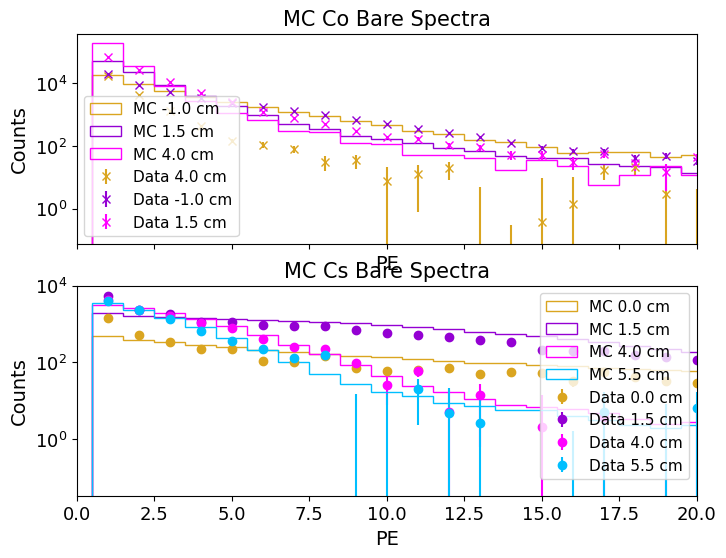

[0.0, 1.5, 4.0, 5.5]


In [81]:

fig, (ax1, ax2) = plt.subplots(figsize=(8,6), nrows=2, sharex=True)
ax = ax1
for mc, dat in zip(mc1.mCoBareList, rds.mCo):
  
  line = dat.mpl_errorbar(ax1, label=f"Data {32-dat.height} cm", marker="x", linestyle="None")
  
  dataArea = np.sum(dat.BkgCorrected_rawCounts)
  
  mcArea = np.sum(mc.mRaw_Counts)
  
  scale = 2*dataArea/mcArea
  
  # mc.mpl_errorbar(ax1, scale=scale, hshift = 0.1, label=f"MC {mc.mRunPars.gammaHeight} cm", marker="X", linestyle="None")
  mc.mpl_hist(ax1, scale = scale, hshift = 0, label=f"MC {mc.mRunPars.gammaHeight} cm", histtype='step', color = line.get_color())
  print(type(mc))

for mc, dat in zip(mc1.mCsBareList, rds.mCs[::-1]):
  # print(dat.height)
  # if 32-dat.height < 1:
  #   continue
  line = dat.mpl_errorbar(ax2, label=f"Data {32-dat.height} cm", marker="o", linestyle="None")
  
  dataArea = np.sum(dat.BkgCorrected_rawCounts)
  
  mcArea = np.sum(mc.mRaw_Counts)
  
  scale = dataArea/mcArea
  
  # mc.mpl_errorbar(ax2, scale=scale, hshift = 0.1, label=f"MC {mc.mRunPars.gammaHeight} cm", marker="x", linestyle="None")
  mc.mpl_hist(ax2, scale = scale, hshift = 0, label=f"MC {mc.mRunPars.gammaHeight} cm", histtype='step', color = line.get_color())

ax1.set_xlim(0, 20)
# ax1.vlines(range(1,11), ymin=1e-3, ymax=1e5, colors='gray', linestyles='dashed', alpha=0.5)
  
  
ax1.set_yscale('log')
ax.set_xlabel("PE")
ax.set_ylabel("Counts")
ax.set_title("MC Co Bare Spectra")

ax2.set_yscale('log')
ax2.set_xlabel("PE")
ax2.set_ylabel("Counts")
ax2.set_title("MC Cs Bare Spectra")

ax1.legend()
ax2.legend(loc='upper right')

plt.show()

print([mc.mRunPars.gammaHeight for mc in mc1.mCsBareList])

---
### RC MC comparisons

To properly do comparison, must use the number of counts in the real data. so data corrected counts = raw counts - bkg rate x run time

In [82]:
comp1 = COMP.Comparator(rds)
comp1.hScale = compConfig["experiment"]["heightScale"]
comp1.mMCDataSet = mc1

# mc1.print()
# print("\n ---------------- \n")
# # rds.print(verbose=1, hScale = 0)
# print("\n ---------------- \n")
# comp1.SetBinRanges(1, 5, mode="value")
# res = mc1.findRunByHeight(3.5, key="colp")  # Test findRunByHeight
# print(mc1.gammaMap.keys())
# print(res)

print(comp1.ValidKeys)

def changeMCAllruns_height(mcHolder, h1, h2=6, stringCheck = "5cm"):
  eps = 0.1
  ## check name of pBath3
  if stringCheck in pBatch3:
    for run in mcHolder.mAllRuns:
      if np.abs(run.mRunPars.gammaHeight-h1) < eps:
        print("Found 5cm run, modifying height to 6cm for comparison")
        run.mRunPars.gammaHeight = h2
  else:
    print("-- changed no heights --\n")
    return None
  return None
# changeMCAllruns_height(mc1, h1=5, h2=6, stringCheck="swapped5cm")

comp1.auto_map_by_common_heights(keys = ["cob", "csb"], heightSkipList=hSkipList, verbose = 1)
# comp1.RemovePairByHeight(key = "csb", height=1.5)
# comp1.print(mcVerb = 1, dataVerb = 1)

# comp1.SetBinRanges(firstBin=2, lastBin = 8, mode="value", verbose=0);
comp1.SetBinRanges_byCountLimit(firstBin=compConfig["comparison"]["compBin_low"], countLimit=compConfig["comparison"]["compCounts_high"], option=compConfig["comparison"]["countOption"], verbose=1)
print("analyzing keys:", comp1.keysUsed)

if 1.5 not in compConfig["comparison"]["hSkipList"]:
  comp1.SetBinRange_forRun(key="csb", height=1.5, firstBin=compConfig["comparison"]["specialCsSkip_bin"], mode = "value")

comp1.GuessOverallScaling()
gsc_co = comp1.statsCo.nuisGuess
gsc_cs = comp1.statsCs.nuisGuess

print("Guessed scaling for Co:", gsc_co)
print("Guessed scaling for Cs:", gsc_cs)

['csb', 'cob', 'cslp', 'colp']
Mapped cob data at height 4.0 cm to MC at height 4.0 cm.
Skipping cob data at height -1.0 cm as it is in the skip list.
Mapped cob data at height 1.5 cm to MC at height 1.5 cm.
Mapped csb data at height 5.5 cm to MC at height 5.5 cm.
Mapped csb data at height 4.0 cm to MC at height 4.0 cm.
Mapped csb data at height 1.5 cm to MC at height 1.5 cm.
Skipping csb data at height 0.0 cm as it is in the skip list.
Comparator.SetBinRanges_byCountLimit: 5 pairs, countLimit=10, option='both'
  h=4.0 Co57: data-limited, cutoff PE=10.00 (last included PE=9.00), nBins=8
  h=1.5 Co57: data+MC-limited, cutoff PE=21.00 (last included PE=20.00), nBins=19
  h=5.5 Cs137: data-limited, cutoff PE=9.00 (last included PE=8.00), nBins=7
  h=4.0 Cs137: data-limited, cutoff PE=12.00 (last included PE=11.00), nBins=10
  h=1.5 Cs137: data-limited, cutoff PE=29.00 (last included PE=28.00), nBins=27
  -> 5 pairs set; 0 with status != 0.
analyzing keys: ['cob', 'csb']
SetBinRange_forRun

Guess for cobalt scaling: 2957.4502484166037
Guess for cesium scaling: 45.41961843949881


Text(0.5, 1.0, 'Chi2 vs Scaling Factor for Cs Bare')

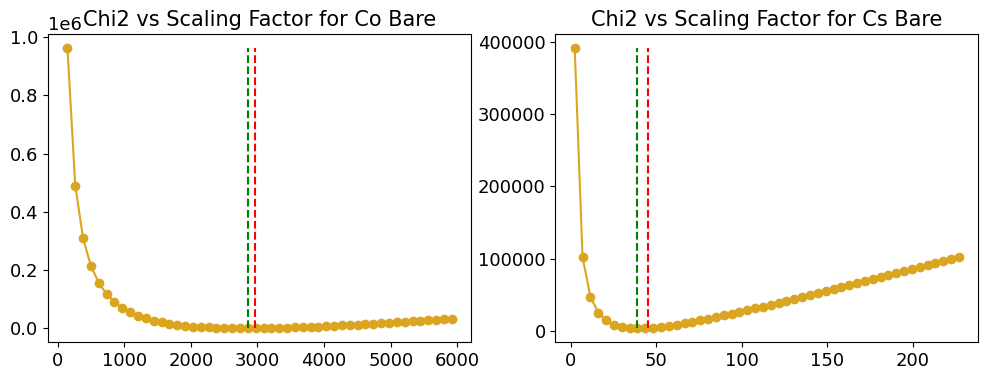

In [83]:
## manual scaling vs automatic minimization check

comp1.minimizeRateScaling(key="csb", manual=True)
comp1.minimizeRateScaling(key="cob", manual=True)

print("Guess for cobalt scaling:", gsc_co)
xScaling_co = np.linspace(gsc_co*0.05, gsc_co*2, 50)
ychi2 = [comp1.CalcKeyChi2(key = "cob", scaling=scale) for scale in xScaling_co]
coScale = xScaling_co[np.argmin(ychi2)] ## testing

print("Guess for cesium scaling:", gsc_cs)
xScaling_cs = np.linspace(gsc_cs*0.05, gsc_cs*5, 50)
ychi2_cs = [comp1.CalcKeyChi2(key = "csb", scaling=scale) for scale in xScaling_cs]
csScale = xScaling_cs[np.argmin(ychi2_cs)] ## testing

fig, (axco, axcs) = plt.subplots(1, 2, figsize=(12, 4))
axco.plot(xScaling_co, ychi2, marker='o')
axco.vlines(gsc_co, ymin=min(ychi2), ymax=max(ychi2), colors='r', linestyles='dashed', label='Guessed Scaling')
axco.vlines(coScale, ymin=min(ychi2), ymax=max(ychi2), colors='g', linestyles='dashed', label='Best Scaling')

axco.set_title("Chi2 vs Scaling Factor for Co Bare")

axcs.plot(xScaling_cs, ychi2_cs, marker='o')
axcs.vlines(gsc_cs, ymin=min(ychi2_cs), ymax=max(ychi2_cs), colors='r', linestyles='dashed', label='Guessed Scaling')
axcs.vlines(csScale, ymin=min(ychi2_cs), ymax=max(ychi2_cs), colors='g', linestyles='dashed', label='Best Scaling')

axcs.set_title("Chi2 vs Scaling Factor for Cs Bare")

In [84]:
## singel scaling value (fixed ratios)
# bb = comp1.GetScaledGuess(keys=["colp", "cslp"], keyRatios=np.array([gsc_co, gsc_cs])/gsc_cs)
# cc = comp1.TotalChi2_singleScaling(scaling=np.average(bb), keys=["colp", "cslp"], keyRatios=np.array([gsc_co, gsc_cs])/gsc_cs)
# print(cc)

# singleScale, resSingle = comp1.minimizeRateScaling(statsOption="dualSource", key=["colp", "cslp"], kwargs={"keyRatios":np.array([actCo/actCs, 1.])}, manual=True)

In [85]:
print("first guess Co scaling:", gsc_co)
print("manually optimized Co scaling:", coScale)

lowScale, result = comp1.minimizeRateScaling(key="cob")
# print("lowScale:", lowScale) # same as below
print("minimizer optimized Co scaling:", comp1.statsCo.nuisScaling)
print("resulting chi2:", comp1.CalcKeyChi2(key = "cob", scaling=comp1.statsCo.nuisScaling))

print("---\nfirst guess Cs scaling:", gsc_cs)
print("manually optimized Cs scaling:", csScale)

lowScale_cs, result_cs = comp1.minimizeRateScaling(key="csb")
# print("lowScale_cs:", lowScale_cs) # same as below
print("minimizer optimized Cs scaling:", comp1.statsCs.nuisScaling)
print("resulting chi2:", comp1.CalcKeyChi2(key = "csb", scaling=comp1.statsCs.nuisScaling))

print("-----\ntotal red chi2 = ", comp1.GetTotalChi2(keys = ['cob', 'csb']))

first guess Co scaling: 2957.4502484166037
manually optimized Co scaling: 2854.844831634803
minimizer optimized Co scaling: 2819.9094698308227
resulting chi2: 481.48226126817434
---
first guess Cs scaling: 45.41961843949881
manually optimized Cs scaling: 38.97744806899847
minimizer optimized Cs scaling: 39.46648665059723
resulting chi2: 3843.9548735571525
-----
total red chi2 =  4325.437134825327


In [86]:
print(len(comp1.csPairs))
print(len(comp1.coPairs))

# print()

3
2


LiteRun 202203101341: plotting background-corrected counts
Cs h=5.5: bins [1-7] -> x=[2.0-8.0]
LiteRun 202203101306: plotting background-corrected counts
Cs h=4.0: bins [1-10] -> x=[2.0-11.0]
LiteRun 202203101150: plotting background-corrected counts
Cs h=1.5: bins [2-27] -> x=[3.0-28.0]
2
LiteRun 202203031411: plotting background-corrected counts
Co h=4.0: bins [1-8] -> x=[2.0-9.0]
LiteRun 202203041257: plotting background-corrected counts
Co h=1.5: bins [1-19] -> x=[2.0-20.0]


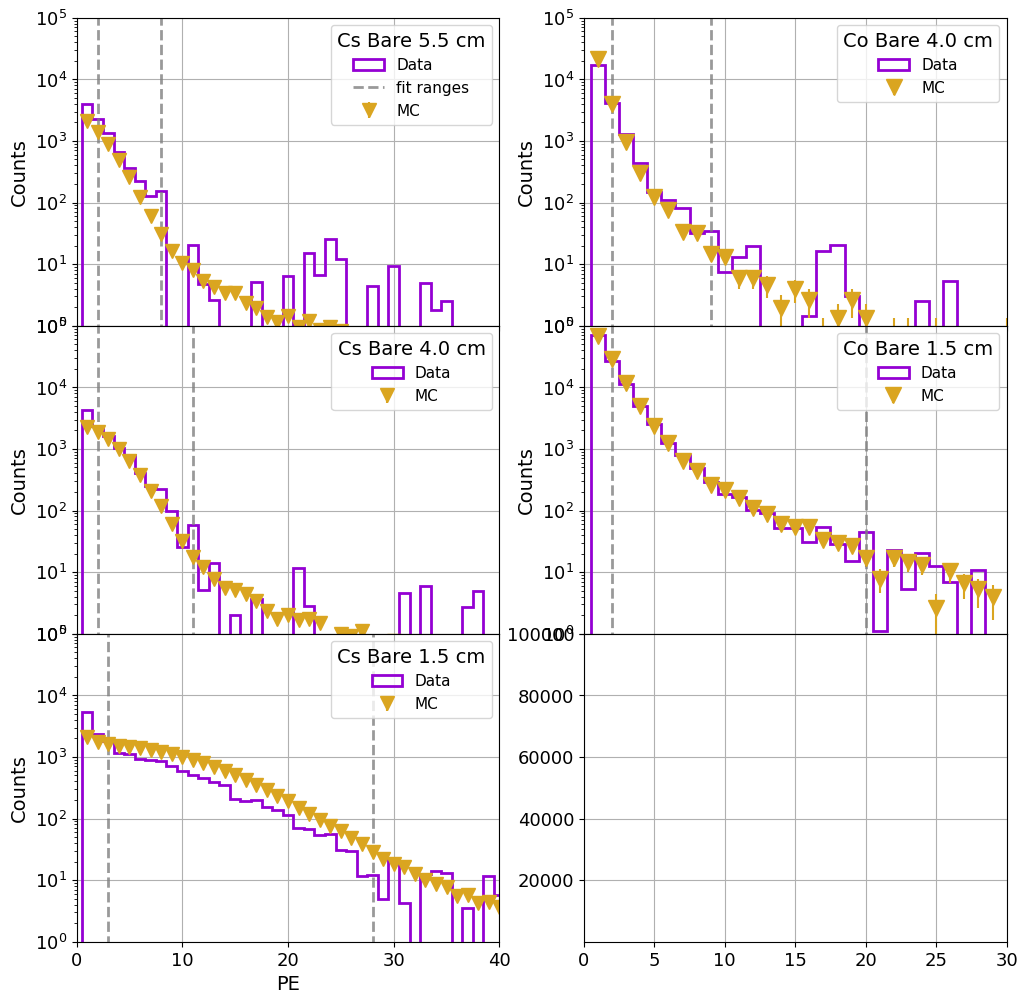

In [87]:
## can we plot the overlayed histograms at the best scaling?

nrows = max(len(comp1.csPairs), len(comp1.coPairs))
fig, axes = plt.subplots(nrows, 2, figsize=(12, 4*nrows), sharex='col')
axA = axes[:, 0]  # First column (Cs)
axB = axes[:, 1]  # Second column (Co)

ms.ResetColorCycle()
color1 = ms.air.col
color2 = ms.lxe.col

## cs plots
for i, pair in enumerate(comp1.csPairs):
  ax = axA[i]
  csScale = lowScale_cs * pair.GetPrefac()
  pair.rc.mpl_hist(ax, verbose = 1, label=f"Data", histtype='step', color = color2, linewidth = 2.)
  pair.mc.mpl_errorbar(ax, scale=csScale, hshift = 0.0, marker="v", linestyle="None", color = color1, markersize=10, label="MC")
  
  ## vertical lines from StatsManager bin positions (specific to each pair)
  fx_fromBin = pair.rc.mBinX[pair.stats.firstBin]
  lx_fromBin = pair.rc.mBinX[pair.stats.lastBin]
  print(f"Cs h={pair.height:.1f}: bins [{pair.stats.firstBin}-{pair.stats.lastBin}] -> x=[{fx_fromBin:.1f}-{lx_fromBin:.1f}]")
  vline_label = "fit ranges" if i == 0 else "_nolegend_"
  ax.vlines([fx_fromBin, lx_fromBin], ymin=1e-3, ymax=1e5, linewidth=2, colors='gray', linestyles='dashed', alpha=0.8, label=vline_label)
  
  legend = ax.legend(title=f"Cs Bare {comp1.hScale-pair.rc.height:.1f} cm")
  legend.get_title().set_fontsize('medium')
  ax.set_ylabel("Counts")
  ax.set_yscale('log')
  if i < len(comp1.csPairs) - 1:
    ax.tick_params(labelbottom=False)
  else:
    ax.set_xlabel("PE")

print(len(comp1.coPairs))
for i, pair in enumerate(comp1.coPairs):
  ax = axB[i]
  coScale = comp1._statsMap.get('cob').nuisScaling * pair.GetPrefac()
  pair.rc.mpl_hist(ax, verbose = 1, label=f"Data", histtype='step', color = color2, linewidth = 2.)
  pair.mc.mpl_errorbar(ax, scale=coScale, hshift = 0.0, marker="v", linestyle="None", color = color1, markersize=12, label="MC")
  
  ## vertical lines from StatsManager bin positions (specific to each pair)
  fx_fromBin = pair.rc.mBinX[pair.stats.firstBin]
  lx_fromBin = pair.rc.mBinX[pair.stats.lastBin]
  print(f"Co h={pair.height:.1f}: bins [{pair.stats.firstBin}-{pair.stats.lastBin}] -> x=[{fx_fromBin:.1f}-{lx_fromBin:.1f}]")
  ax.vlines([fx_fromBin, lx_fromBin], ymin=1e-3, ymax=1e5, linewidth=2, colors='gray', linestyles='dashed', alpha=0.8)
  
  legend = ax.legend(title=f"Co Bare {comp1.hScale-pair.rc.height:.1f} cm")
  legend.get_title().set_fontsize('medium')
  ax.set_ylabel("Counts")
  ax.set_yscale('log')
  if i < len(comp1.coPairs) - 1:
    ax.tick_params(labelbottom=False)
  else:
    ax.set_xlabel("PE")

axs = np.append(axA, axB)
[ax.set_xlim(0, 40) for ax in axA];
[ax.set_xlim(0, 30) for ax in axB];

[ax.set_ylim(1, 1e5) for ax in axs];

[ax.grid() for ax in axs];
plt.subplots_adjust(hspace=0.0)
plt.show()


LiteRun 202203101341: plotting background-corrected counts
LiteRun 202203101306: plotting background-corrected counts
LiteRun 202203031411: plotting background-corrected counts
LiteRun 202203041257: plotting background-corrected counts


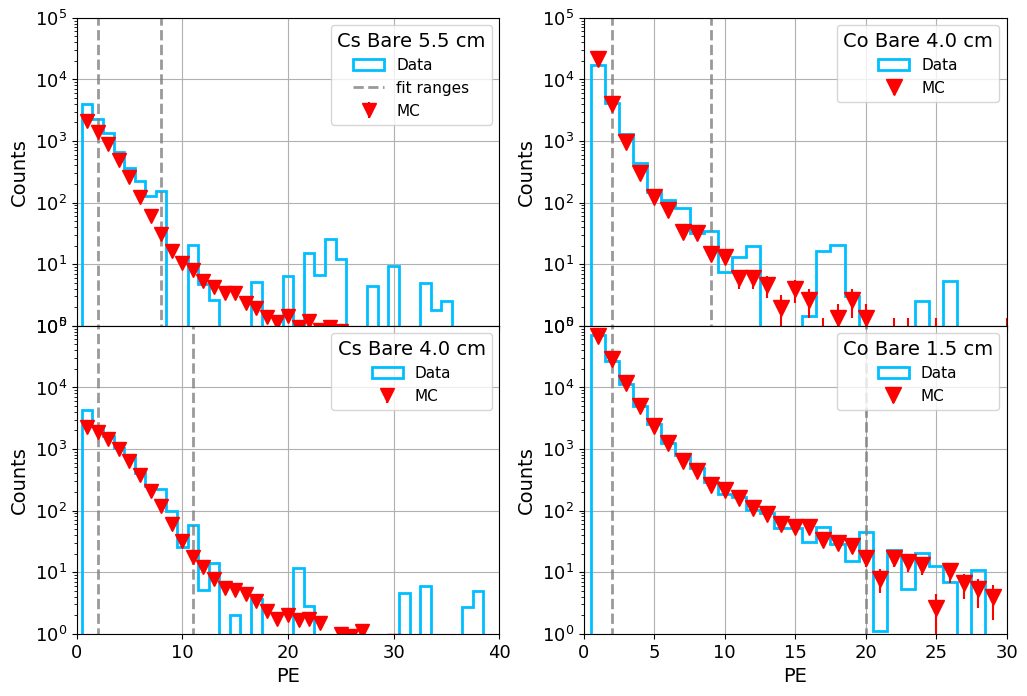

In [88]:
# Same plot, excluding Cs 1.5 cm
csPairs_plot = [p for p in comp1.csPairs if abs(p.height - 1.5) > 0.3]

nrows = max(len(csPairs_plot), len(comp1.coPairs))
fig, axes = plt.subplots(nrows, 2, figsize=(12, 4*nrows), sharex='col')
axA = axes[:, 0]
axB = axes[:, 1]

ms.ResetColorCycle()
color1 = ms.red.col
color2 = ms.cf4.col

for i, pair in enumerate(csPairs_plot):
    ax = axA[i]
    csScale = lowScale_cs * pair.GetPrefac()
    pair.rc.mpl_hist(ax, verbose=1, label='Data', histtype='step', color=color2, linewidth=2.)
    pair.mc.mpl_errorbar(ax, scale=csScale, hshift=0.0, marker='v', linestyle='None', color=color1, markersize=10, label='MC')
    fx = pair.rc.mBinX[pair.stats.firstBin]
    lx = pair.rc.mBinX[pair.stats.lastBin]
    vline_label = 'fit ranges' if i == 0 else '_nolegend_'
    ax.vlines([fx, lx], ymin=1e-3, ymax=1e5, linewidth=2, colors='gray', linestyles='dashed', alpha=0.8, label=vline_label)
    legend = ax.legend(title=f'Cs Bare {comp1.hScale-pair.rc.height:.1f} cm')
    legend.get_title().set_fontsize('medium')
    ax.set_ylabel('Counts'); ax.set_yscale('log')
    if i < len(csPairs_plot) - 1:
        ax.tick_params(labelbottom=False)
    else:
        ax.set_xlabel('PE')

for i in range(len(csPairs_plot), nrows):  # hide unused Cs axes
    axA[i].set_visible(False)

for i, pair in enumerate(comp1.coPairs):
    ax = axB[i]
    coScale = comp1._statsMap.get('cob').nuisScaling * pair.GetPrefac()
    pair.rc.mpl_hist(ax, verbose=1, label='Data', histtype='step', color=color2, linewidth=2.)
    pair.mc.mpl_errorbar(ax, scale=coScale, hshift=0.0, marker='v', linestyle='None', color=color1, markersize=12, label='MC')
    fx = pair.rc.mBinX[pair.stats.firstBin]
    lx = pair.rc.mBinX[pair.stats.lastBin]
    ax.vlines([fx, lx], ymin=1e-3, ymax=1e5, linewidth=2, colors='gray', linestyles='dashed', alpha=0.8)
    legend = ax.legend(title=f'Co Bare {comp1.hScale-pair.rc.height:.1f} cm')
    legend.get_title().set_fontsize('medium')
    ax.set_ylabel('Counts'); ax.set_yscale('log')
    if i < len(comp1.coPairs) - 1:
        ax.tick_params(labelbottom=False)
    else:
        ax.set_xlabel('PE')

[ax.set_xlim(0, 40) for ax in axA[:len(csPairs_plot)]]
[ax.set_xlim(0, 30) for ax in axB]
[ax.set_ylim(1, 1e5) for ax in np.append(axA[:len(csPairs_plot)], axB)]
[ax.grid() for ax in np.append(axA[:len(csPairs_plot)], axB)]
plt.subplots_adjust(hspace=0.0)
plt.show()

---
### Full dataset analysis

In [89]:
print(os.listdir(mcDataPath))

# check if comp1 exists before trying to delete
if 'comp1' in locals():
  print("deleted comp1")
  del comp1
if 'mc1' in locals():
  print("deleted mc1")
  del mc1

['0', '1', '4', '3', '2', '5']
deleted comp1
deleted mc1


In [90]:
## making MC dataset - collect results silently, print summary at end
chis = []
lyList = []
scaling = []
guessScale = []
nbeamList = []
binInfoList = []  # Store bin range info including warnings

totalChis = []

dual = False
showSubrows = False  # Toggle to show/hide per-pair bin info

comp = COMP.Comparator(rds)
sortedListDir = sorted(os.listdir(mcDataPath))

# Suppress prints during loop - collect everything
import io
import contextlib

for folder in sortedListDir:
  
  # Capture any stray output from MCdataSet loading
  with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    mc = MCH.MCdataSet(mcDataPath+folder+"/", buildOptions='all', skipRootHeights=hSkipList, verbose=0)
    
    ly = mc.mAllRuns[0].mPhysPars.ly
    nbeam = mc.mAllRuns[0].Nbeam
    print("LY here:", ly)
    if ly < 1: # garbage
      continue
    
    ## add CA correction here
    mc.doCAcorrection_BinomialMC(compConfig["mc_analysis"]["NCA"]) # makes var mNPE_corr
    
    # changeMCAllruns_height(mc, h1=5, h2=6, stringCheck="swapped5cm")
    
    mc.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"], variable='mNPE') #mNPE_corr
    mc.check_physPars_andDetPars(verbose=0)
  
  comp.hScale = compConfig["experiment"]["heightScale"]
  comp.mMCDataSet = mc
  
  comp.auto_map_by_common_heights(keys=["cob", "csb"], heightSkipList=hSkipList, verbose=0)
  # comp.RemovePairByHeight(key = "csb", height=1.5)
  
  ## by low lim on byCountLimit goes by bins, so 1 excludes 1PE (first) bin
  ## SetBinRanges, mode = value goes by x value, so firstBin = 1 includes 1PE (0th bin) and above
  if compConfig["comparison"]["compFlag"] == "fixed":
    binInfo = comp.SetBinRanges(firstBin=compConfig["comparison"]["compPE_low"], lastBin=compConfig["comparison"]["compPE_high"], mode="value", verbose=0)
  elif compConfig["comparison"]["compFlag"] == "countLimit":
    binInfo = comp.SetBinRanges_byCountLimit(firstBin=compConfig["comparison"]["compBin_low"], countLimit=compConfig["comparison"]["compCounts_high"], option=compConfig["comparison"]["countOption"], verbose=0)
  else:
    raise ValueError(f"Invalid compFlag: {compConfig['comparison']['compFlag']}")
  
  # Per-run overrides applied after global bin-setting (any mode)
  if 1.5 not in compConfig["comparison"]["hSkipList"]:
    comp.SetBinRange_forRun(key="csb", height=1.5, firstBin=compConfig["comparison"]["specialCsSkip_bin"], mode="value", verbose=0)
  
  comp.GuessOverallScaling(keys=["cob", "csb"])
  
  # print("guess after", comp._statsMap['cslp'].nuisGuess)
  # print("scaling before", comp._statsMap['cslp'].nuisScaling)
  
  scale1, fitRes = comp.minimizeRateScaling(key="csb", manual=True, statsOption = "single")
  chi2_val = comp.CalcKeyChi2(key="csb", scaling = scale1)
  # print("func return", scale1, fitRes)
  # print("scaling after", comp._statsMap['cslp'].nuisScaling)
  
  scale2, fitRes2 = comp.minimizeRateScaling(key="cob", manual=True, statsOption = "single")
  chi2_val2 = comp.CalcKeyChi2(key="cob", scaling = scale2)
  ## rerun with good values to reset internal stats trackers
  
  scaling.append([scale1, scale2])
  guessScale.append([comp.GetStats("csb").nuisGuess, comp.GetStats("cob").nuisGuess])
  
  chis.append([chi2_val, chi2_val2])
  lyList.append(ly)
  nbeamList.append(nbeam)
  binInfoList.append(binInfo)
  
  totalChi2 = chi2_val + chi2_val2
  calculatedTotalChi2 = comp.GetTotalChi2(keys=["cob", "csb"])
  summedTotalChi2 = chi2_val + chi2_val2
  
  totalNbins = comp.GetTotalNBins(keys=["cob", "csb"])
  reducedChi2 = totalChi2/(totalNbins-2)
  totalChis.append([totalChi2, totalNbins, reducedChi2])

# Sort by LY
sorted_indices = np.argsort(lyList)
lyList = np.array(lyList)[sorted_indices]
chis = np.array(chis)[sorted_indices]
scaling = np.array(scaling)[sorted_indices]
guessScale = np.array(guessScale)[sorted_indices]
nbeamList = np.array(nbeamList)[sorted_indices]
binInfoList = [binInfoList[i] for i in sorted_indices]

totalChis = np.array(totalChis)[sorted_indices]
totalChiOnly = totalChis[:,0]
nBinsOnly = totalChis[:,1]
redChiOnly = totalChis[:,2]

### Printing ###
# Helper to format binInfo row
def fmt_binInfo(info):
  return f"{info.get('source','?')[:4]:<6} {info.get('height','?'):<6} {info.get('nBins','?'):<5} [{info.get('firstBinX',0):.0f}-{info.get('lastBinX',0):.0f}]"

# Print clean summary table
if showSubrows:
  print(f"{'Folder':<7} {'LY':<5} {'Scale':<10} {'Chi2':<10} | {'Src':<6} {'Ht':<6} {'nBin':<5} {'Range':<10}")
  print("="*75)
  for i, folder in enumerate(np.array(sortedListDir)[sorted_indices]):
    for j, info in enumerate(binInfoList[i]):
      if j == 0:
        print(f"{folder:<7} {lyList[i]:<5.1f} {scaling[i,0]:<10.3f} {chis[i,0]:<10.1f} | {fmt_binInfo(info)}")
      else:
        print(f"{'':<35} | {fmt_binInfo(info)}")
    print("-"*75)
else:
  print(f"{'Folder':<7} {'LY':<5} {'Scale(Cs)':<10} {'Scale(Co)':<10} {'Chi2(Cs)':<10} {'Chi2(Co)':<10}")
  print("="*70)
  for i, folder in enumerate(np.array(sortedListDir)[sorted_indices]):
    print(f"{folder:<7} {lyList[i]:<5.1f} {scaling[i,0]:<10.3f} {scaling[i,1]:<10.3f} {chis[i,0]:<10.1f} {chis[i,1]:<10.1f}")
  print("-"*70)

print(f"\nTotal folders: {len(lyList)}")

# Low-stat warnings summary
warnings = [(f, lyList[i], info) for i, f in enumerate(np.array(sortedListDir)[sorted_indices]) 
            for info in binInfoList[i] if info.get('status') == -1]
if warnings:
  print(f"\n⚠️ {len(warnings)} pairs with low MC stats (bins < countLimit in range)")

Folder  LY    Scale(Cs)  Scale(Co)  Chi2(Cs)   Chi2(Co)  
0       3.5   40.925     3016.465   4119.6     695.7     
1       3.8   39.478     2790.677   3844.0     487.6     
5       3.9   39.002     2737.817   3802.9     304.3     
2       4.0   38.265     2630.554   3766.2     261.6     
3       4.2   38.228     2467.391   3817.1     260.8     
4       4.8   37.365     2255.372   4227.1     307.9     
----------------------------------------------------------------------

Total folders: 6


scaleCo: [3016.46450587 2790.67673817 2737.81743288 2630.55448451 2467.39133604
 2255.37249461]
scaleCs: [40.92530213 39.47750294 39.00197933 38.26493614 38.22767422 37.3654877 ]
--------

skipping heights [-1, 0]
comparing via method: countLimit
count limit: 1 10
min ly: 4.0 min chi2: 4027.7823289032426
-------
fit success True
fit minimum at LY = 4.07 +/- 0.00
minimum chi2 = 4027.78 +/- 0.07
width error on chi2 0.025028488991013252
bestFit_scaleCo: 2548.9729
bestFit_scaleCs: 38.2463


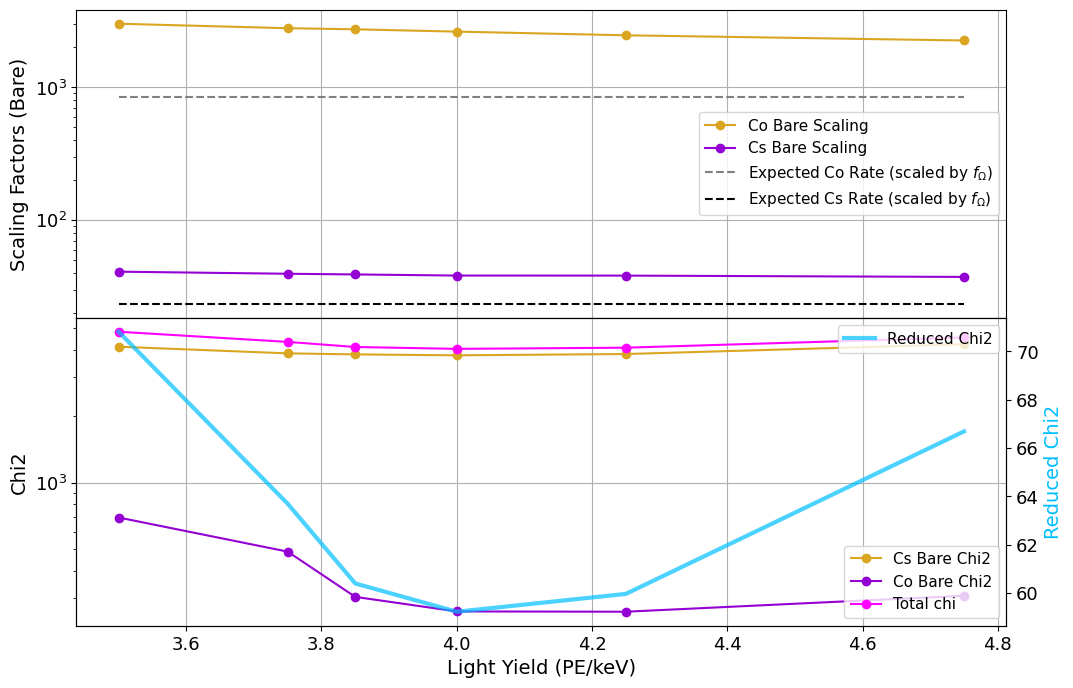

In [91]:
fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(12, 8), height_ratios=[1, 1], sharex=True)

import CompHelpers.Fitters as FTS

if not dual:
  scaleCs = np.array([scale[0] for scale in scaling])  # index 0 = csb (scale1)
  scaleCo = np.array([scale[1] for scale in scaling])  # index 1 = cob (scale2)

  print("scaleCo:", scaleCo)
  print("scaleCs:", scaleCs)

  ms.ResetColorCycle()
  ax1.plot(lyList, scaleCo, marker='o', label='Co Bare Scaling', color=ms.GetNextColor())
  ax1.plot(lyList, scaleCs, marker='o', label='Cs Bare Scaling', color=ms.GetNextColor())

  fsCo = fOmega * actCo
  fsCs = fOmega * actCs
  ax1.hlines(fsCo, xmin=min(lyList), xmax=max(lyList), colors='gray', linestyles='dashed', label=r'Expected Co Rate (scaled by $f_\Omega$)')
  ax1.hlines(fsCs, xmin=min(lyList), xmax=max(lyList), colors='black', linestyles='dashed', label=r'Expected Cs Rate (scaled by $f_\Omega$)')

  bb1 = [c[0]+c[1] for c in chis]
  bbCs = [c[0] for c in chis]
  bbCo = [c[1] for c in chis]

  ms.ResetColorCycle()
  ax3.plot(lyList, bbCs, marker='o', label='Cs Bare Chi2', color=ms.GetNextColor())
  ax3.plot(lyList, bbCo, marker='o', label='Co Bare Chi2', color=ms.GetNextColor())
  ax3.plot(lyList, bb1, marker='o', label='Total chi', color=ms.GetNextColor())

  ax4 = ax3.twinx()
  ax4.plot(lyList, redChiOnly, label='Reduced Chi2', color=ms.GetNextColor(), linewidth=3, alpha=0.7)

elif dual:
  ax3.plot(lyList, chis, marker='o', label='Total chi2 (single scaling)')

print("--------\n\nskipping heights", hSkipList)
print("comparing via method:", compConfig["comparison"]["compFlag"])

if compConfig["comparison"]["compFlag"] == "countLimit":
  print("count limit:", compConfig["comparison"]["compBin_low"], compConfig["comparison"]["compCounts_high"])
elif compConfig["comparison"]["compFlag"] == "fixed":
  print("PE range:", compConfig["comparison"]["compPE_low"], "-", compConfig["comparison"]["compPE_high"])

#### Fitting ####
minLYvalue = lyList[np.argmin(totalChiOnly)]
minLYindex = np.argmin(totalChiOnly)
print("min ly:", minLYvalue, "min chi2:", min(totalChiOnly))

chiToPass = totalChiOnly
if minLYvalue <= 2:
  chiToPass = redChiOnly

if True: # do the fit
  res, outstr = FTS.fit_quadratic_minimum(lyList[minLYindex-1:minLYindex+2], chiToPass[minLYindex-1:minLYindex+2])
  print("-------\nfit success", res['success'])
  print(f"fit minimum at LY = {res['x0']:.2f} +/- {res['x0_err']:.2f}")
  print(f"minimum chi2 = {res['y0']:.2f} +/- {res['y0_err']:.2f}")
  print("width error on chi2", 1/np.sqrt(res['a']))

  minXfromFit = res['x0']
  x_fit = np.linspace(lyList[minLYindex-1], lyList[minLYindex+1], 100)
  y_fit = FTS.quadratic(x_fit, res['a'], res['x0'], res['y0'])

  ## compute the 'true' rate scaling parameter at the fit minimum and compare to expected
  # really we will just take the average of the two neighboring points.abs
  diffs = np.abs(lyList - minXfromFit)
  closest_two = np.argsort(diffs)[:2]
  bestFit_scaleCo = np.mean(scaleCo[closest_two])
  bestFit_scaleCs = np.mean(scaleCs[closest_two])
  print(f"bestFit_scaleCo: {bestFit_scaleCo:.4f}")
  print(f"bestFit_scaleCs: {bestFit_scaleCs:.4f}")

ax1.set_ylabel("Scaling Factors (Bare)")
ax1.legend()
ax1.set_yscale('log')
ax1.grid(True)

ax3.set_ylabel("Chi2")
ax3.set_xlabel("Light Yield (PE/keV)")
ax3.legend(loc='lower right')
ax3.grid(True)
ax3.set_yscale("log")

ax4.set_xlabel("Light Yield (PE/keV)")
ax4.legend()
ax4.set_ylabel("Reduced Chi2", color=ms.cf4.col)

plt.subplots_adjust(hspace=0.)


In [92]:
## Systematic scan: firstBin x heightSkip combinations
# Uses SetBinRanges_byCountLimit for all cases
# Fits quadratic to total chi2 vs LY for each case

import CompHelpers.Fitters as FTS

# firstBin_list = [0, 1]  # 0-based bin indices: 1 -> 2PE, 2 -> 3PE
firstBin_list = [1, 2]  # 0-based bin indices: 1 -> 2PE, 2 -> 3PE

hSkip_configs = {
    "all":        [-1, 0.0],
    "skip 5.5cm": [-1, 0.0, 5.5],
    "skip 1.5cm": [-1, 0.0, 1.5]
}

countLim = compConfig["comparison"]["compCounts_high"]

scan_results = {}
i = 0

for fb in firstBin_list:
  for hLabel, hSkip in hSkip_configs.items():
    tag = f"firstBin={fb}, {hLabel}"

    lyArr = []
    totalChi2Arr = []
    totalNbinsArr = []
    scaleCoArr = []
    scaleCsArr = []

    compS = COMP.Comparator(rds)
    i += 1

    for folder in sorted(os.listdir(mcDataPath)):
      with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        mcS = MCH.MCdataSet(mcDataPath+folder+"/", buildOptions='all', skipRootHeights=hSkip, verbose=0)
        ly = mcS.mAllRuns[0].mPhysPars.ly
        if ly < 1:
          continue
        mcS.doCAcorrection_BinomialMC(compConfig["mc_analysis"]["NCA"])
        mcS.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"], variable='mNPE')
        mcS.check_physPars_andDetPars(verbose=0)
        changeMCAllruns_height(mcS, h1=5, h2=6, stringCheck="swapped5cm")

      compS.hScale = compConfig["experiment"]["heightScale"]
      compS.mMCDataSet = mcS
      compS.auto_map_by_common_heights(keys=["cob", "csb"], heightSkipList=hSkip, verbose=0)
      compS.SetBinRanges_byCountLimit(firstBin=fb, countLimit=countLim, option=compConfig["comparison"]["countOption"], verbose=-1)
      # compS.SetBinRanges(firstBin=fb+1, lastBin=compConfig["comparison"]["compPE_high"], mode="value", verbose=0)
      
      # Override only the lower bin for the Cs 1.5 cm dataset
      if 1.5 not in hSkip:
        compS.SetBinRange_forRun(key="csb", height=1.5, firstBin=compConfig["comparison"]["specialCsSkip_bin"], mode = "value")
      compS.GuessOverallScaling(keys=["cob", "csb"])

      s1, _ = compS.minimizeRateScaling(key="csb", manual=True, statsOption="single")
      chi2_cs = compS.CalcKeyChi2(key="csb", scaling=s1)

      s2, _ = compS.minimizeRateScaling(key="cob", manual=True, statsOption="single")
      chi2_co = compS.CalcKeyChi2(key="cob", scaling=s2)

      lyArr.append(ly)
      totalChi2Arr.append(chi2_cs + chi2_co)
      totalNbinsArr.append(compS.GetTotalNBins(keys=["cob", "csb"]))
      scaleCoArr.append(s2)
      scaleCsArr.append(s1)

    # Sort by LY
    idx = np.argsort(lyArr)
    lyArr = np.array(lyArr)[idx]
    totalChi2Arr = np.array(totalChi2Arr)[idx]
    totalNbinsArr = np.array(totalNbinsArr)[idx]
    reducedChi2Arr = totalChi2Arr/(totalNbinsArr - 2)
    scaleCoArr = np.array(scaleCoArr)[idx]
    scaleCsArr = np.array(scaleCsArr)[idx]

    # Fit quadratic
    print("--\nfitting case:", tag)

    # Check total chi2 min
    minLYvalue = lyArr[np.argmin(totalChi2Arr)]  # if total chi2 min is at edge, skip fit
    minLYindex = np.argmin(totalChi2Arr)
    minLY_reduced = lyArr[np.argmin(reducedChi2Arr)]

    res = None
    resReduced = None
    bestFit_scaleCo = None
    bestFit_scaleCs = None
    print("min ly at:", lyArr[minLYindex])
    if minLYvalue != min(lyArr) and minLYvalue != max(lyArr):
      res, outstr = FTS.fit_quadratic_minimum(lyArr[minLYindex-1:minLYindex+2], totalChi2Arr[minLYindex-1:minLYindex+2])
      print(outstr)
      # print("counter:", i)

      # find the two closest scaleCo/scaleCs values to the fit minimum x
      diffs = np.abs(lyArr - res['x0'])
      closest_two = np.argsort(diffs)[:2]
      bestFit_scaleCo = np.mean(scaleCoArr[closest_two])
      bestFit_scaleCs = np.mean(scaleCsArr[closest_two])

    # if minLY_reduced != 1 and minLY_reduced != 7:
    #   resReduced = FTS.fit_quadratic_minimum(lyArr[minLYindex-1:minLYindex+2], reducedChi2Arr[minLYindex-1:minLYindex+2])
    resReduced = None

    scan_results[tag] = {
        'ly': lyArr,
        'totalChi2': totalChi2Arr,
        'reducedChi2': reducedChi2Arr,
        'totalNbins': totalNbinsArr,
        'fit': res,
        'fitReduced': resReduced,
        'bestFit_scaleCo': bestFit_scaleCo,
        'bestFit_scaleCs': bestFit_scaleCs,
    }


SetBinRange_forRun: patched key='csb' h=1.5cm -> bins [2, 27] (x: 3.00 to 28.00), nBins=26
SetBinRange_forRun: patched key='csb' h=1.5cm -> bins [2, 27] (x: 3.00 to 28.00), nBins=26
SetBinRange_forRun: patched key='csb' h=1.5cm -> bins [2, 27] (x: 3.00 to 28.00), nBins=26
SetBinRange_forRun: patched key='csb' h=1.5cm -> bins [2, 27] (x: 3.00 to 28.00), nBins=26
SetBinRange_forRun: patched key='csb' h=1.5cm -> bins [2, 27] (x: 3.00 to 28.00), nBins=26
SetBinRange_forRun: patched key='csb' h=1.5cm -> bins [2, 27] (x: 3.00 to 28.00), nBins=26
--
fitting case: firstBin=1, all
min ly at: 4.0
Fit results: x0 = 4.071 ± 0.001, y0 = 4027.782 ± 0.066, a = 1596.360 ± 17.940, success = True
SetBinRange_forRun: patched key='csb' h=1.5cm -> bins [2, 27] (x: 3.00 to 28.00), nBins=26
SetBinRange_forRun: patched key='csb' h=1.5cm -> bins [2, 27] (x: 3.00 to 28.00), nBins=26
SetBinRange_forRun: patched key='csb' h=1.5cm -> bins [2, 27] (x: 3.00 to 28.00), nBins=26
SetBinRange_forRun: patched key='csb' h

In [93]:
print("\n\n=== Systematic Scan Summary ===")

# Total chi2 fits
print(f"\n--- Total χ² fits ---")
print(f"{'Case':<30} {'LY_min':>8} {'± LY':>8} {'χ²_min':>8} {'nBins*':>7} {'redχ²':>7} {'scaleCo':>10} {'scaleCs':>10} {'fit ok':>6}")
print("=" * 100)
for tag, r in scan_results.items():
    fit = r['fit']
    bfCo = r.get('bestFit_scaleCo')
    bfCs = r.get('bestFit_scaleCs')
    if fit is not None:
      nBins_at_min = r['totalNbins'][np.argmin(np.abs(r['ly'] - fit['x0']))]
      redChi2_at_min = fit['y0'] / (nBins_at_min - 2)
      scaleCo_str = f"{bfCo:.4f}" if bfCo is not None else "  N/A  "
      scaleCs_str = f"{bfCs:.4f}" if bfCs is not None else "  N/A  "
      print(f"{tag:<30} {fit['x0']:>8.2f} {fit['x0_err']:>8.2f} {fit['y0']:>8.1f} {nBins_at_min:>7.0f} {redChi2_at_min:>7.2f} {scaleCo_str:>10} {scaleCs_str:>10} {'✓' if fit['success'] else '✗':>6}")
    else:
      print(f"{tag:<30} {'(min at edge, skipped)':>70}")

print(f"\n* nBins at the LY closest to the fitted minimum")




=== Systematic Scan Summary ===

--- Total χ² fits ---
Case                             LY_min     ± LY   χ²_min  nBins*   redχ²    scaleCo    scaleCs fit ok
firstBin=1, all                    4.07     0.00   4027.8      70   59.23  2548.9729    38.2463      ✓
firstBin=1, skip 5.5cm             3.91     0.00   2386.6      63   39.12  2684.1860    34.1993      ✓
firstBin=1, skip 1.5cm             4.13     0.00    720.5      25   31.33  2773.7011    51.2475      ✓
firstBin=2, all                    4.26     0.00   3085.0      66   48.20  2617.3564    35.0063      ✓
firstBin=2, skip 5.5cm             3.91     0.00   1959.5      60   33.78  2796.1708    32.4689      ✓
firstBin=2, skip 1.5cm                                                         (min at edge, skipped)

* nBins at the LY closest to the fitted minimum


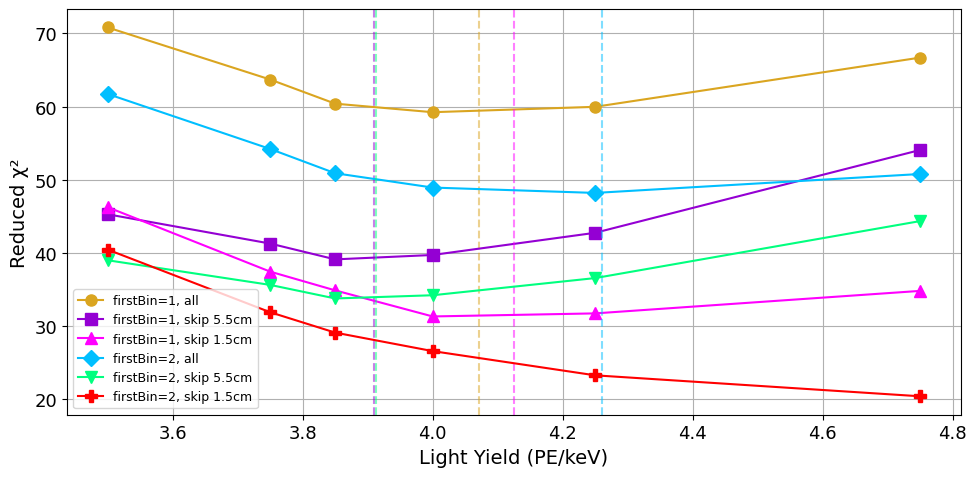

In [94]:
## Plot reduced chi2 vs LY for each systematic case
markers = ['o', 's', '^', 'D', 'v', 'P', '*', 'X', 'h', '+']
fig, ax = plt.subplots(figsize=(10, 5))

for i, (tag, r) in enumerate(scan_results.items()):
    fit = r['fit']
    marker = markers[i % len(markers)]
    line, = ax.plot(r['ly'], r['reducedChi2'], marker=marker, label=tag, markersize=8, linestyle='-')
    if fit is not None and fit['success']:
        ax.axvline(fit['x0'], color=line.get_color(), linestyle='dashed', alpha=0.5)

ax.set_xlabel("Light Yield (PE/keV)")
ax.set_ylabel("Reduced χ²")
# ax.set_title("Bare SiPM Systematic Scan: Reduced χ² vs LY")
ax.legend(fontsize=9)
ax.grid(True)
# ax.set_yscale('log')
plt.tight_layout()
plt.show()


In [95]:
## compute weighted average LY + uncertainty from scan fits
valid_fits = [r['fit'] for r in scan_results.values() if r['fit'] is not None and r['fit']['success']]

if valid_fits:
    x = np.array([fit['x0'] for fit in valid_fits], dtype=float)
    chi2min = np.array([fit['y0'] for fit in valid_fits], dtype=float)

    # Keep your original weighting choice: w = 1/chi2_min
    w = 1.0 / np.clip(chi2min, 1e-12, None)
    wsum = np.sum(w)
    weighted_avg_ly = np.sum(w * x) / wsum

    # Uncertainty estimate 1: weighted spread of fitted minima
    weighted_var = np.sum(w * (x - weighted_avg_ly) ** 2) / wsum
    weighted_std = np.sqrt(weighted_var)

    # Effective sample size for weighted data
    neff = (wsum ** 2) / np.sum(w ** 2)
    weighted_sem = weighted_std / np.sqrt(neff) if neff > 1 else np.nan

    print(f"\nWeighted average (1/chi2) LY from valid fits: {weighted_avg_ly:.2f} PE/keV")
    print(f"Weighted spread (w-std): ±{weighted_std:.2f} PE/keV")
    if np.isfinite(weighted_sem):
        print(f"Error on weighted mean (w-SEM): ±{weighted_sem:.2f} PE/keV (N_eff={neff:.2f})")
    else:
        print("Error on weighted mean (w-SEM): undefined (need >1 effective fit)")

    # Optional uncertainty estimate 2: weighted by 1/fit uncertainty if available
    x0_err = np.array([fit.get('x0_err', np.nan) for fit in valid_fits], dtype=float)
    good_err = np.isfinite(x0_err) & (x0_err > 0)
    if np.any(good_err):
        w_err = 1.0 / (x0_err[good_err] ** 2)
        x_err = x[good_err]
        ly_ivw = np.sum(w_err * x_err) / np.sum(w_err)
        ly_ivw_err = np.sqrt(1.0 / np.sum(w_err))
        print(f"Inverse fit error LY (using x0_err): {ly_ivw:.2f} ± {ly_ivw_err:.2f} PE/keV")
else:
    print("\nNo valid fits to compute weighted average LY")


Weighted average (1/chi2) LY from valid fits: 4.07 PE/keV
Weighted spread (w-std): ±0.12 PE/keV
Error on weighted mean (w-SEM): ±0.06 PE/keV (N_eff=3.30)
Inverse fit error LY (using x0_err): 3.97 ± 0.00 PE/keV
